In [1]:
# Imports
import os
import random
import pandas as pd
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, ConcatDataset, DataLoader
from torchvision import models
from google.colab import drive
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torchvision.transforms import functional as TF
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import multiprocessing
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
from torch.optim.lr_scheduler import ReduceLROnPlateau
import seaborn as sns
from torch.optim.lr_scheduler import CosineAnnealingLR
import zipfile
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Sampler

In [2]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Paths on Google Drive
ZIP_PATH = '/content/drive/MyDrive/Dataset_Severity_V2.zip'
CSV_PATH = '/content/drive/MyDrive/Dataset_Severity_V2.csv'

# 3. Unzip frames to Colab
import zipfile, os

EXTRACT_PATH = "/content/Dataset_Severity_V2"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

# Automatically resolve image root
contents = os.listdir(EXTRACT_PATH)
assert len(contents) == 1 or any(os.path.isdir(os.path.join(EXTRACT_PATH, d)) for d in contents)

if len(contents) == 1 and os.path.isdir(os.path.join(EXTRACT_PATH, contents[0])):
    IMAGE_ROOT = os.path.join(EXTRACT_PATH, contents[0])
else:
    IMAGE_ROOT = EXTRACT_PATH

print("Resolved IMAGE_ROOT:", IMAGE_ROOT)
print("Exists:", os.path.exists(IMAGE_ROOT))

num_videos = len([
    d for d in os.listdir(IMAGE_ROOT)
    if os.path.isdir(os.path.join(IMAGE_ROOT, d))
])
print("Number of videos:", num_videos)


Mounted at /content/drive
Resolved IMAGE_ROOT: /content/Dataset_Severity_V2/Dataset_Severity_V2
Exists: True
Number of videos: 645


In [3]:
from torch.utils.data import Dataset
from PIL import Image
import torch
import os

class CataractDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform
        self.label_map = {
            "low": 0,
            "dense": 1,
            "mature": 2,
            "brunescent": 3
        }

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        img_path = os.path.join(
            self.image_dir,
            row["videoname"],
            row["filename"]
        )

        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Missing image: {img_path}")

        image = Image.open(img_path).convert("RGB")
        label = torch.tensor(
            self.label_map[row["label"]],
            dtype=torch.long
        )

        if self.transform:
            image = self.transform(image)

        return image, label


In [4]:
# ============================================================
#                     AUGMENTATION UTILS
# ============================================================

def _mean_rgb(image: Image.Image):
    arr = np.array(image.convert("RGB"))
    return tuple(arr.reshape(-1, 3).mean(axis=0).astype(np.uint8).tolist())


class PadToSquareWithMean:
    def __call__(self, image: Image.Image):
        w, h = image.size
        max_dim = max(w, h)
        pad_left = (max_dim - w) // 2
        pad_top = (max_dim - h) // 2
        pad_right = max_dim - w - pad_left
        pad_bottom = max_dim - h - pad_top
        mean_color = _mean_rgb(image)
        return TF.pad(
            image,
            (pad_left, pad_top, pad_right, pad_bottom),
            fill=mean_color,
            padding_mode='constant'
        )


class RotateWithMeanFill:
    def __init__(self, degrees=12):
        self.degrees = degrees

    def __call__(self, image: Image.Image):
        angle = transforms.RandomRotation.get_params([-self.degrees, self.degrees])
        mean_color = _mean_rgb(image)
        return TF.rotate(image, angle=angle, expand=False, fill=mean_color)


class AffineWithMeanFill:
    def __init__(self, degrees=0, translate=(0.08, 0.08),
                 scale=(0.95, 1.05), shear=(-5, 5)):
        self.degrees = degrees
        self.translate = translate
        self.scale = scale
        self.shear = shear

    def __call__(self, image: Image.Image):
        angle, translations, scale, shear = transforms.RandomAffine.get_params(
            degrees=(-self.degrees, self.degrees),
            translate=self.translate,
            scale_ranges=self.scale,
            shears=self.shear,
            img_size=image.size
        )
        mean_color = _mean_rgb(image)
        return TF.affine(
            image,
            angle=angle,
            translate=translations,
            scale=scale,
            shear=shear,
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=mean_color
        )


# ============================================================
#                 NORMALIZATION CONSTANTS
# ============================================================
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ============================================================
#                 BASE TRANSFORM (NO AUG)
# ============================================================
base_transform = transforms.Compose([
    PadToSquareWithMean(),
    transforms.Resize((260, 260)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


# ============================================================
#                 AUGMENTED TRANSFORM (TRAIN)
# ============================================================
# aug_transform = transforms.Compose([
#     PadToSquareWithMean(),
#     transforms.Resize((260, 260)),

#     # --- Geometry ---
#     RotateWithMeanFill(degrees=12),
#     transforms.RandomHorizontalFlip(p=0.3),
#     transforms.RandomVerticalFlip(p=0.1),
#     AffineWithMeanFill(
#         degrees=0,
#         translate=(0.10, 0.10),
#         scale=(0.95, 1.05),
#         shear=(-4, 4)
#     ),

#     # --- Photometric ---
#     transforms.RandomApply([
#         transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.10)
#     ], p=0.6),

#     transforms.RandomApply([
#         transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.2))
#     ], p=0.3),

#     transforms.Resize((260, 260))

#     # transforms.ToTensor(),
#     # transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
# ])
aug_transform = transforms.Compose([
    PadToSquareWithMean(),
    transforms.Resize((260, 260)),

    # --- Geometry ---
    RotateWithMeanFill(degrees=12),
    transforms.RandomHorizontalFlip(p=0.3),
    # transforms.RandomVerticalFlip(p=0.1),
    AffineWithMeanFill(
        degrees=0,
        translate=(0.10, 0.10),
        scale=(0.95, 1.05),
        shear=(-4, 4)
    ),

    # --- Photometric ---
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.10)
    ], p=0.6),

    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.2))
    ], p=0.3),

    # --- MOST IMPORTANT ---
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])



In [5]:
df = pd.read_csv(CSV_PATH)
print(df.shape)


(2541, 6)


In [6]:
# ========== Load and Prepare CSV ==========
df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

# Derive label column from binary indicators
df["label"] = None
df.loc[df["low nuclear density"] == 1.0, "label"] = "low"
df.loc[df["dense"] == 1.0, "label"] = "dense"
df.loc[df["mature"] == 1.0, "label"] = "mature"
df.loc[df["brunescent"] == 1.0, "label"] = "brunescent"

# Keep only valid rows
df = df[df["label"].notna()].reset_index(drop=True)

# ------------------------------------------------
# ADD videoname (folder name) from disk structure
# ------------------------------------------------
IMAGE_ROOT = "/content/Dataset_Severity_V2/Dataset_Severity_V2"

filename_to_video = {}
for videoname in os.listdir(IMAGE_ROOT):
    video_path = os.path.join(IMAGE_ROOT, videoname)
    if not os.path.isdir(video_path):
        continue
    for fname in os.listdir(video_path):
        filename_to_video[fname] = videoname

df["videoname"] = df["filename"].map(filename_to_video)

# Safety check
missing = df["videoname"].isna().sum()
assert missing == 0, f"{missing} images missing videoname mapping"

# Keep only required columns
df = df[["filename", "videoname", "label"]]


Image path: /content/Dataset_Severity_V2/Dataset_Severity_V2/RE_0502_S1_0502/RE_0502_S1_0502_frame488_Sec244.00.jpg
Label     : mature


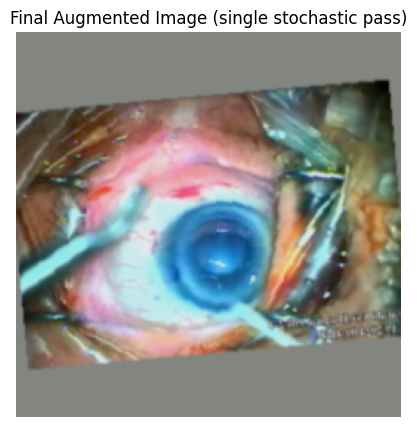

Applied augmentations:
  HorizontalFlip: True
  ColorJitter: True
  GaussianBlur: True


In [7]:
# ============================================================
#     SINGLE AUGMENTATION PASS WITH PROBABILITY LOGGING
# ============================================================

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF


# ------------------------------------------------------------
# ImageNet normalization (must match training)
# ------------------------------------------------------------
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def _mean_rgb(image: Image.Image):
    arr = np.array(image.convert("RGB"))
    return tuple(arr.reshape(-1, 3).mean(axis=0).astype(np.uint8).tolist())


def denormalize(tensor):
    img = tensor.permute(1, 2, 0).cpu().numpy()
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)


# ------------------------------------------------------------
# Custom transforms (same as training)
# ------------------------------------------------------------
class PadToSquareWithMean:
    def __call__(self, image):
        w, h = image.size
        max_dim = max(w, h)
        pad_l = (max_dim - w) // 2
        pad_t = (max_dim - h) // 2
        pad_r = max_dim - w - pad_l
        pad_b = max_dim - h - pad_t
        return TF.pad(
            image,
            (pad_l, pad_t, pad_r, pad_b),
            fill=_mean_rgb(image)
        )


class RotateWithMeanFill:
    def __init__(self, degrees=12):
        self.degrees = degrees

    def __call__(self, image):
        angle = transforms.RandomRotation.get_params(
            [-self.degrees, self.degrees]
        )
        return TF.rotate(image, angle, fill=_mean_rgb(image))


# ------------------------------------------------------------
# Debug wrapper for probabilistic transforms
# ------------------------------------------------------------
class DebugRandomApply:
    def __init__(self, transform, p, name):
        self.transform = transform
        self.p = p
        self.name = name
        self.applied = False

    def __call__(self, image):
        if random.random() < self.p:
            self.applied = True
            return self.transform(image)
        else:
            self.applied = False
            return image


# ------------------------------------------------------------
# Define probabilistic transforms (same probabilities)
# ------------------------------------------------------------
debug_hflip = DebugRandomApply(
    transforms.RandomHorizontalFlip(p=1.0),
    p=0.3,
    name="HorizontalFlip"
)

debug_color = DebugRandomApply(
    transforms.ColorJitter(
        brightness=0.25,
        contrast=0.25,
        saturation=0.10
    ),
    p=0.6,
    name="ColorJitter"
)

debug_blur = DebugRandomApply(
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.2)),
    p=0.3,
    name="GaussianBlur"
)


# ------------------------------------------------------------
# One-pass augmentation function
# ------------------------------------------------------------
def apply_debug_augmentation(image):
    logs = {}

    img = PadToSquareWithMean()(image)
    img = transforms.Resize((260, 260))(img)
    img = RotateWithMeanFill(degrees=12)(img)

    img = debug_hflip(img)
    logs["HorizontalFlip"] = debug_hflip.applied

    img = debug_color(img)
    logs["ColorJitter"] = debug_color.applied

    img = debug_blur(img)
    logs["GaussianBlur"] = debug_blur.applied

    img = transforms.ToTensor()(img)
    img = transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )(img)

    return img, logs


# ------------------------------------------------------------
# Pick ONE real image from your dataset
# ------------------------------------------------------------
sample = df.sample(1).iloc[0]

img_path = os.path.join(
    IMAGE_ROOT,
    sample["videoname"],
    sample["filename"]
)

print("Image path:", img_path)
print("Label     :", sample["label"])

original_img = Image.open(img_path).convert("RGB")


# ------------------------------------------------------------
# Apply augmentation ONCE
# ------------------------------------------------------------
aug_tensor, applied_logs = apply_debug_augmentation(original_img)
aug_img = denormalize(aug_tensor)


# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------
plt.figure(figsize=(5, 5))
plt.imshow(aug_img)
plt.title("Final Augmented Image (single stochastic pass)")
plt.axis("off")
plt.show()


# ------------------------------------------------------------
# Log which augmentations fired
# ------------------------------------------------------------
print("Applied augmentations:")
for k, v in applied_logs.items():
    print(f"  {k}: {v}")


In [8]:
class BalancedClassSampler(Sampler):
    """
    Ensures a FIXED number of samples per class per epoch.
    Sampling is done WITH replacement.
    """

    def __init__(self, labels, target_per_class: dict):
        """
        labels: array of integer labels (e.g. 0,1,2,3)
        target_per_class: dict {class_id: target_samples}
        """
        self.labels = np.asarray(labels)
        self.target_per_class = target_per_class
        self.classes = np.unique(self.labels)

        self.class_indices = {
            c: np.where(self.labels == c)[0]
            for c in self.classes
        }

        # sanity check
        for c in self.classes:
            if c not in self.target_per_class:
                raise ValueError(f"No target defined for class {c}")

    def __iter__(self):
        indices = []

        for c in self.classes:
            target_n = self.target_per_class[c]
            chosen = np.random.choice(
                self.class_indices[c],
                target_n,
                replace=True
            )
            indices.extend(chosen.tolist())

        np.random.shuffle(indices)
        return iter(indices)

    def __len__(self):
        return sum(self.target_per_class.values())


In [9]:
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, WeightedRandomSampler
import multiprocessing
import numpy as np
import torch

# ============================================================
#        PATIENT-WISE (VIDEO-WISE) TRAIN / VAL / TEST SPLIT
# ============================================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(df, groups=df["videoname"])
)

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df  = df.iloc[temp_idx].reset_index(drop=True)

label_map = {
    "low": 0,
    "dense": 1,
    "mature": 2,
    "brunescent": 3
}

y_train = train_df["label"].map(label_map).to_numpy()

TARGET_PER_CLASS = {
    0: 1200,  # low
    1: 1200,  # dense
    2: 1200,  # mature
    3: 400    # brunescent
}

balanced_sampler = BalancedClassSampler(
    labels=y_train,
    target_per_class=TARGET_PER_CLASS
)


print("Samples per epoch:", len(balanced_sampler))


gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(temp_df, groups=temp_df["videoname"])
)

val_df  = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

# ============================================================
#        VERIFY NO PATIENT LEAKAGE (MANDATORY)
# ============================================================

assert len(set(train_df.videoname) & set(val_df.videoname)) == 0
assert len(set(train_df.videoname) & set(test_df.videoname)) == 0
assert len(set(val_df.videoname) & set(test_df.videoname)) == 0

print("✓ Patient-wise split verified (no leakage)")

# ============================================================
#                 DATASETS
# ============================================================

train_dataset = CataractDataset(
    train_df,
    IMAGE_ROOT,
    transform=aug_transform
)

val_dataset = CataractDataset(
    val_df,
    IMAGE_ROOT,
    transform=base_transform
)

test_dataset = CataractDataset(
    test_df,
    IMAGE_ROOT,
    transform=base_transform
)

# ============================================================
#                 DATALOADERS
# ============================================================

BATCH_SIZE = 64
num_cpu = multiprocessing.cpu_count()

train_loader_normal = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=balanced_sampler,   # <-- IMPORTANT
    shuffle=False,               # MUST be False when sampler is used
    num_workers=num_cpu // 2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_cpu // 2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_cpu // 2,
    pin_memory=True
)


Samples per epoch: 4000
Train: 1802, Val: 394, Test: 345
✓ Patient-wise split verified (no leakage)


In [10]:
from collections import Counter

epoch_labels = []

for _, labels in train_loader_normal:
    epoch_labels.extend(labels.numpy())

print(Counter(epoch_labels))


Counter({np.int64(0): 1200, np.int64(1): 1200, np.int64(2): 1200, np.int64(3): 400})


In [11]:
import torch.nn as nn
from torchvision import models

def efficientnet_b2(weights="DEFAULT", fine_tune=True, num_classes=4):
    """
    EfficientNet-B2 adapted for cataract classification.

    Fine-tuning policy:
    - Freeze all layers
    - Unfreeze last two MBConv blocks + classifier
    """

    # 1) Load pretrained backbone
    eff_weights = (
        models.EfficientNet_B2_Weights.DEFAULT if weights == "DEFAULT" else weights
    )
    model = models.efficientnet_b2(weights=eff_weights)

    # 2) Freeze / unfreeze
    if fine_tune:
        for p in model.parameters():
            p.requires_grad = False

        for name, p in model.named_parameters():
            if name.startswith(("figure.5", "features.6", "features.7", "classifier")):
                p.requires_grad = True

    # 3) Replace classifier head
    in_feats = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_feats, num_classes)

    return model


Using device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 89.6MB/s]


Epoch [1/30] | Train Loss: 1.0021 | Val Loss: 0.8215 | Val Acc: 0.7462
✓ Saved best model at epoch 1
Epoch [2/30] | Train Loss: 0.6022 | Val Loss: 0.6719 | Val Acc: 0.8096
✓ Saved best model at epoch 2
Epoch [3/30] | Train Loss: 0.4812 | Val Loss: 0.6302 | Val Acc: 0.8249
✓ Saved best model at epoch 3
Epoch [4/30] | Train Loss: 0.4252 | Val Loss: 0.6166 | Val Acc: 0.8350
✓ Saved best model at epoch 4
Epoch [5/30] | Train Loss: 0.4062 | Val Loss: 0.6085 | Val Acc: 0.8376
✓ Saved best model at epoch 5
Epoch [6/30] | Train Loss: 0.3802 | Val Loss: 0.6064 | Val Acc: 0.8401
✓ Saved best model at epoch 6
Epoch [7/30] | Train Loss: 0.3523 | Val Loss: 0.6255 | Val Acc: 0.8452
Epoch [8/30] | Train Loss: 0.3539 | Val Loss: 0.6180 | Val Acc: 0.8376
Epoch [9/30] | Train Loss: 0.3439 | Val Loss: 0.6069 | Val Acc: 0.8503
Epoch [10/30] | Train Loss: 0.3219 | Val Loss: 0.6005 | Val Acc: 0.8503
✓ Saved best model at epoch 10
Epoch [11/30] | Train Loss: 0.3082 | Val Loss: 0.6109 | Val Acc: 0.8503
Epoch 

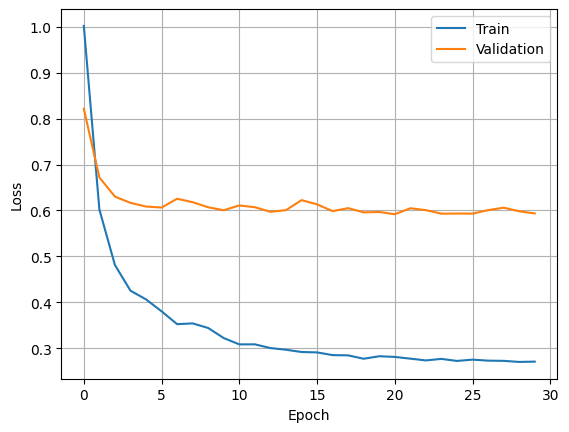

In [13]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

num_epochs = 30
best_val_loss = float("inf")
SAVE_PATH = "efficientnet_b3_best.pth"   # name fix (optional)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = efficientnet_b2(fine_tune=True).to(device)

weights = torch.tensor(
    [1.0, 1.0, 1.0, 2.0], device=device)

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05, weight=weights)

optimizer = torch.optim.AdamW(
    [
        {"params": model.features.parameters(), "lr": 2e-5},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

train_loss, valid_loss = [], []

for epoch in range(num_epochs):
    # ---------------- TRAIN ----------------
    model.train()
    running_loss = 0.0
    total_train = 0

    for imgs, lbls in train_loader_normal:
        imgs = imgs.to(device)
        lbls = lbls.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(imgs)
        loss = loss_fn(outputs, lbls)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        total_train += imgs.size(0)

    epoch_train_loss = running_loss / total_train
    train_loss.append(epoch_train_loss)

    # ---------------- VALIDATE ----------------
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs = imgs.to(device)
            lbls = lbls.to(device)

            outputs = model(imgs)
            loss = loss_fn(outputs, lbls)

            running_val_loss += loss.item() * imgs.size(0)
            total += imgs.size(0)

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == lbls).sum().item()

    epoch_val_loss = running_val_loss / total
    val_acc = correct / total
    valid_loss.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # ---------------- SCHEDULER ----------------
    scheduler.step(epoch_val_loss)

    # ---------------- SAVE BEST ----------------
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"✓ Saved best model at epoch {epoch+1}")

# ---------------- PLOT ----------------
plt.figure()
plt.plot(train_loss, label="Train")
plt.plot(valid_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()



TEST RESULTS
              precision    recall  f1-score   support

         low     0.8429    0.9752    0.9042       121
       dense     0.8647    0.7770    0.8185       148
      mature     0.7536    0.7647    0.7591        68
  brunescent     1.0000    0.3750    0.5455         8

    accuracy                         0.8348       345
   macro avg     0.8653    0.7230    0.7568       345
weighted avg     0.8383    0.8348    0.8305       345

Overall Accuracy : 0.8348
Macro F1-score   : 0.7568
Weighted F1-score: 0.8305


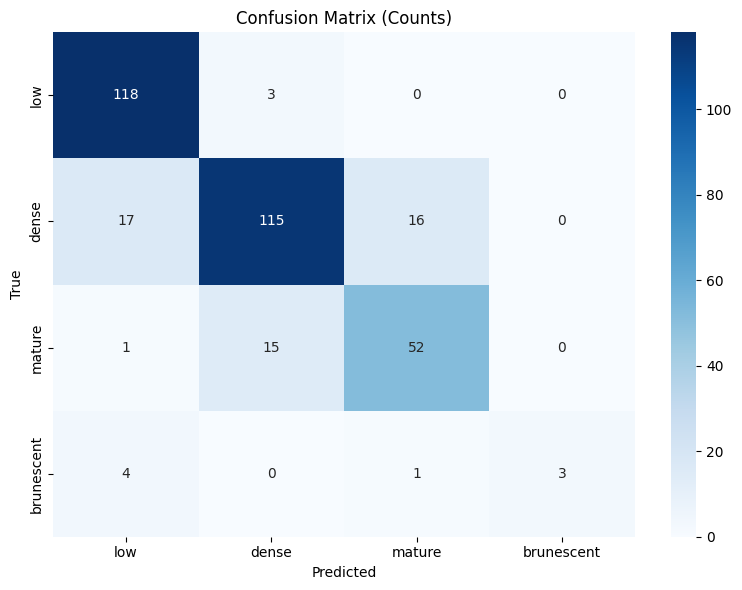

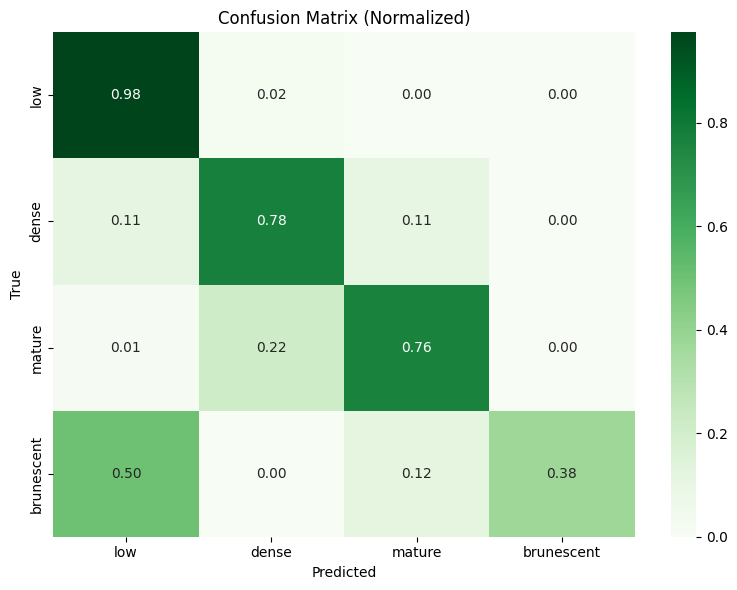

In [14]:
classes = ["low", "dense", "mature", "brunescent"]

# Load best model
model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        lbls = lbls.to(device)

        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(lbls.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# ---------------- Metrics ----------------
print("\nTEST RESULTS")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=classes,
        digits=4
    )
)

print(f"Overall Accuracy : {accuracy_score(all_labels, all_preds):.4f}")
print(f"Macro F1-score   : {f1_score(all_labels, all_preds, average='macro'):.4f}")
print(f"Weighted F1-score: {f1_score(all_labels, all_preds, average='weighted'):.4f}")

# ---------------- Confusion Matrix ----------------
cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (Counts)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (Normalized)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()